# 07 — Grad-CAM Investigation: InceptionResNetV2 LP-FT Tier 5

**Cross-source explainability analysis: HAM10000 vs BCN_20000 vs MSK**

**Model used:** `experiments/inceptionresnetv2/tier5/B_lpft/best.keras`

Justificare: LP-FT depășește final-Optuna pe toate cele 5 tier-uri pentru
InceptionResNetV2 (70.35% vs 60.41% test acc la Tier 5). Folosim LP-FT ca
model operațional pentru investigație, nu modelul Optuna.

**Metodologie (identică cu Notebook 07 EfficientNet pentru comparabilitate):**
1. Inferență pe test set, salvăm `image_id`, `source`, `confidence`, `correct`
2. Trei seturi per clasă × sursă:
   - **Set A**: HAM10000 corecte (high confidence)
   - **Set B**: BCN_20000 incorecte (high confidence — model încrezător dar greșit)
   - **Set C**: BCN_20000 corecte (high confidence — control)
3. Grad-CAM pe layer-ul `conv_7b_ac` (ultimul conv block + activare în InceptionResNetV2)
4. Plot grids per clasă × set + observații cross-source

**Rulează celulele în ordine, una câte una.**

## 1. Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Imports & Config

**⚠️ Verifică `TFRECORD_DIR` și `MODEL_PATH` — ajustează dacă structura ta diferă.**

In [2]:
import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
from pathlib import Path

# === PATHS ===
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
EXP_DIR = DRIVE_BASE / 'experiments' / 'inceptionresnetv2' / 'tier5' / 'B_lpft'
MODEL_PATH = EXP_DIR / 'final.keras'
TFRECORD_DIR = Path("/content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords/test")  # AJUSTEAZĂ dacă e altă cale

OUTPUT_DIR = EXP_DIR / 'gradcam_lpft'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# === CLASSES ===
CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
N_CLASSES = len(CLASS_NAMES)

# === MODEL CONFIG ===
IMG_SIZE = 224
BATCH_SIZE = 32
BACKBONE_LAYER_NAME_HINT = 'inception_resnet_v2'  # numele submodelului
TARGET_CONV_LAYER = 'conv_7b_ac'  # last conv activation in InceptionResNetV2

print(f'Model: {MODEL_PATH}')
print(f'Exists: {MODEL_PATH.exists()}')
print(f'TFRecords dir: {TFRECORD_DIR}')
print(f'Output dir: {OUTPUT_DIR}')

Model: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/B_lpft/final.keras
Exists: True
TFRecords dir: /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords/test
Output dir: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/B_lpft/gradcam_lpft


## 3. TFRecord parser + sanity check

Features așteptate: `image_bytes`, `lesion_id`, `image_id`, `source`, `label`.

In [3]:
FEATURE_DESCRIPTION = {
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
}


def parse_tfrecord(example_proto):
    parsed = tf.io.parse_single_example(example_proto, FEATURE_DESCRIPTION)
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)
    # InceptionResNetV2 preprocessing: (x / 127.5) - 1.0  (same as EfficientNet here)
    img = (img / 127.5) - 1.0
    return {
        'image':     img,
        'label':     parsed['label'],
        'image_id':  parsed['image_id'],
        'lesion_id': parsed['lesion_id'],
        'source':    parsed['source'],
    }


def build_test_dataset():
    files = sorted([str(p) for p in TFRECORD_DIR.glob('*.tfrec')])
    if not files:
        files = sorted([str(p) for p in TFRECORD_DIR.glob('*.tfrecord')])
    if not files:
        raise FileNotFoundError(f'No TFRecord files found in {TFRECORD_DIR}')
    print(f'Found {len(files)} TFRecord shards')
    return (tf.data.TFRecordDataset(files)
              .map(parse_tfrecord, num_parallel_calls=tf.data.AUTOTUNE))


# Sanity check
ds_check = build_test_dataset().take(2)
for sample in ds_check:
    print(f"image shape: {sample['image'].shape}, dtype: {sample['image'].dtype}")
    print(f"image range: [{tf.reduce_min(sample['image']).numpy():.3f}, "
          f"{tf.reduce_max(sample['image']).numpy():.3f}]")
    print(f"label: {sample['label'].numpy()} ({CLASS_NAMES[int(sample['label'].numpy())]})")
    print(f"image_id: {sample['image_id'].numpy().decode()}")
    print(f"source: {sample['source'].numpy().decode()}")
    print('---')

Found 3 TFRecord shards
image shape: (224, 224, 3), dtype: <dtype: 'float32'>
image range: [-0.913, 0.698]
label: 5 (nv)
image_id: ISIC_0000007
source: other
---
image shape: (224, 224, 3), dtype: <dtype: 'float32'>
image range: [-0.818, 0.646]
label: 5 (nv)
image_id: ISIC_0000012
source: other
---


## 4. Load model (LP-FT best.keras)

`compile=False` pentru că modelul a fost antrenat cu focal loss; nu mai antrenăm,
doar facem inferență + Grad-CAM.

In [4]:
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
model.summary()

Model: "InceptionResNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_resnet_v2             │ (None, 5, 5, 1536)     │    54,336,736 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,573,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_203         │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_204         │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,179,943 (214.31 MB)

 Trainable params: 56,086,567 (213.95 MB)

 Non-trainable params: 93,376 (364.75 KB)

## 5. Inferență pe test set + image_id tracking

Salvăm `df_pred` cu `image_id`, `source`, `true_label`, `pred_label`, `confidence`,
și probabilitățile per clasă. Dacă fișierul există deja, îl reîncărcăm — economie de timp.

In [5]:
PRED_WITH_IDS_CSV = OUTPUT_DIR / 'test_predictions_with_ids.csv'

if PRED_WITH_IDS_CSV.exists():
    print(f'Loading existing: {PRED_WITH_IDS_CSV}')
    df_pred = pd.read_csv(PRED_WITH_IDS_CSV)
else:
    print('Running inference with image_ids...')
    ds = build_test_dataset()
    ds_batched = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    all_image_ids, all_lesion_ids, all_sources = [], [], []
    all_y_true, all_y_pred, all_confidence = [], [], []
    all_probs = []

    for i, batch in enumerate(ds_batched):
        probs = model.predict(batch['image'], verbose=0)
        preds = np.argmax(probs, axis=1)
        confs = np.max(probs, axis=1)

        all_image_ids.extend([s.decode() for s in batch['image_id'].numpy()])
        all_lesion_ids.extend([s.decode() for s in batch['lesion_id'].numpy()])
        all_sources.extend([s.decode() for s in batch['source'].numpy()])
        all_y_true.extend(batch['label'].numpy().tolist())
        all_y_pred.extend(preds.tolist())
        all_confidence.extend(confs.tolist())
        all_probs.append(probs)

        if (i + 1) % 20 == 0:
            print(f'  Batch {i+1}, processed {len(all_image_ids)} images')

    all_probs = np.concatenate(all_probs, axis=0)

    df_pred = pd.DataFrame({
        'image_id': all_image_ids,
        'lesion_id': all_lesion_ids,
        'source': all_sources,
        'true_label': all_y_true,
        'pred_label': all_y_pred,
        'confidence': all_confidence,
    })
    for i, c in enumerate(CLASS_NAMES):
        df_pred[f'prob_{c}'] = all_probs[:, i]

    df_pred.to_csv(PRED_WITH_IDS_CSV, index=False)
    print(f'Saved: {PRED_WITH_IDS_CSV}')

# Coloane derivate
df_pred['true_class'] = df_pred['true_label'].map(lambda i: CLASS_NAMES[int(i)])
df_pred['pred_class'] = df_pred['pred_label'].map(lambda i: CLASS_NAMES[int(i)])
df_pred['correct'] = df_pred['true_label'] == df_pred['pred_label']

# MSK e adesea mapat la 'other' în pipeline-ul nostru — normalizăm
df_pred['source'] = df_pred['source'].replace({'other': 'MSK'})

print(f'\nTotal: {len(df_pred)}')
print(f'Source values: {sorted(df_pred["source"].unique())}')
print(f'\nAccuracy per source:')
print(df_pred.groupby('source')['correct'].agg(['mean', 'count']).round(4))
print(f'\nOverall accuracy: {df_pred["correct"].mean():.4f}')

Running inference with image_ids...
Found 3 TFRecord shards
  Batch 20, processed 640 images
  Batch 40, processed 1280 images
  Batch 60, processed 1920 images
Saved: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/B_lpft/gradcam_lpft/test_predictions_with_ids.csv

Total: 2513
Source values: ['BCN_20000', 'HAM10000', 'MSK']

Accuracy per source:
             mean  count
source                  
BCN_20000  0.6278   1236
HAM10000   0.7939    956
MSK        0.7259    321

Overall accuracy: 0.7035


## 6. Selecție candidați Grad-CAM

Pentru fiecare clasă × set, alegem 3 imagini cu confidence cea mai mare.

In [6]:
N_PER_CLASS_PER_SET = 3


def select_candidates(df, source, correct, n=N_PER_CLASS_PER_SET):
    """Top-N per clasă, filtrate după sursă și corectitudine, sortate după confidence."""
    sub = df[(df['source'] == source) & (df['correct'] == correct)].copy()
    selected = (sub.sort_values('confidence', ascending=False)
                   .groupby('true_class', group_keys=False)
                   .head(n))
    return selected.sort_values(['true_class', 'confidence'], ascending=[True, False])


set_A = select_candidates(df_pred, 'HAM10000',  correct=True)   # HAM corecte
set_B = select_candidates(df_pred, 'BCN_20000', correct=False)  # BCN incorecte (high conf)
set_C = select_candidates(df_pred, 'BCN_20000', correct=True)   # BCN corecte (control)

print('=== Set A: HAM correct (high conf) ===')
print(set_A[['true_class', 'pred_class', 'image_id', 'confidence']].to_string(index=False))
print('\n=== Set B: BCN incorrect (high conf — confidently wrong) ===')
print(set_B[['true_class', 'pred_class', 'image_id', 'confidence']].to_string(index=False))
print('\n=== Set C: BCN correct (high conf — control) ===')
print(set_C[['true_class', 'pred_class', 'image_id', 'confidence']].to_string(index=False))

set_A.to_csv(OUTPUT_DIR / 'set_A_HAM_correct.csv', index=False)
set_B.to_csv(OUTPUT_DIR / 'set_B_BCN_incorrect.csv', index=False)
set_C.to_csv(OUTPUT_DIR / 'set_C_BCN_correct.csv', index=False)

=== Set A: HAM correct (high conf) ===
true_class pred_class     image_id  confidence
     akiec      akiec ISIC_0026525    0.813149
     akiec      akiec ISIC_0026212    0.799893
     akiec      akiec ISIC_0024517    0.672039
       bcc        bcc ISIC_0028106    0.957502
       bcc        bcc ISIC_0028059    0.951194
       bcc        bcc ISIC_0024461    0.918440
       bkl        bkl ISIC_0034259    0.989728
       bkl        bkl ISIC_0025131    0.981622
       bkl        bkl ISIC_0026511    0.976467
        df         df ISIC_0030665    0.997927
        df         df ISIC_0031443    0.997926
        df         df ISIC_0031799    0.996913
       mel        mel ISIC_0032535    0.905278
       mel        mel ISIC_0024732    0.892679
       mel        mel ISIC_0033569    0.880552
        nv         nv ISIC_0029963    0.984102
        nv         nv ISIC_0028772    0.980711
        nv         nv ISIC_0034016    0.977202
      vasc       vasc ISIC_0032890    0.999984
      vasc       vasc

## 7. Inspect layers — confirmă target conv layer

Pentru InceptionResNetV2 vrem `conv_7b_ac` (activare ReLU după conv_7b, ultimul block).
Verificăm că există în submodelul backbone.

In [7]:
# Găsește submodelul backbone
backbone = None
for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        backbone = layer
        print(f'Backbone submodel: {layer.name} (params: {layer.count_params():,})')
        break

if backbone is None:
    raise ValueError('Could not find backbone submodel inside the model')

# Verifică că target layer există
try:
    target = backbone.get_layer(TARGET_CONV_LAYER)
    print(f'\n✓ Target layer: {target.name}')
    print(f'  Output shape: {target.output.shape}')
except ValueError:
    print(f'\n⚠️ "{TARGET_CONV_LAYER}" not found. Listing last 10 backbone layers:')
    for l in backbone.layers[-10:]:
        print(f'  {l.name:40s} | {type(l).__name__:25s} | {l.output.shape}')
    raise

Backbone submodel: inception_resnet_v2 (params: 54,336,736)

✓ Target layer: conv_7b_ac
  Output shape: (None, 5, 5, 1536)


## 8. Build Grad-CAM model

Trick standard: un model cu două output-uri — feature maps de la `conv_7b_ac`
și softmax-ul final. Folosim același input ca modelul original.

In [8]:
backbone_feature_extractor = tf.keras.Model(
    inputs=backbone.input,
    outputs=backbone.get_layer(TARGET_CONV_LAYER).output
)

# Assuming the backbone takes the main model's input directly (or after minimal processing)
# In many of these architectures, model.layers[x] is the backbone.
# A safer way to build grad_model without breaking the graph is:
grad_model = tf.keras.Model(
    inputs=model.input,
    outputs=[backbone_feature_extractor(model.layers[0].output), model.output]
)

# Sanity check
test_input = tf.zeros((1, IMG_SIZE, IMG_SIZE, 3))
fmap, preds = grad_model(test_input, training=False)
print(f'Feature map shape: {fmap.shape}')
print(f'Predictions shape: {preds.shape}')

Feature map shape: (1, 5, 5, 1536)
Predictions shape: (1, 7)


## 9. Compute Grad-CAM

Implementare standard: gradient al output-ului pentru clasa țintă față de feature maps,
weighted average peste canale, ReLU, normalizare.

In [9]:
def compute_gradcam(image_preprocessed, target_class_idx):
    """Grad-CAM heatmap pentru o singură imagine deja preprocesată.

    Args:
        image_preprocessed: tensor [H, W, 3] în [-1, 1]
        target_class_idx: int, clasa pentru care calculăm gradientul
    Returns:
        heatmap: numpy array [h, w] în [0, 1]
    """
    img_batch = tf.expand_dims(tf.constant(image_preprocessed, dtype=tf.float32), 0)

    # Extragem backbone-ul din modelul principal
    backbone_layer = next(l for l in model.layers if isinstance(l, tf.keras.Model))
    # Creăm un model intern care să returneze atât target conv layer cât și output-ul backbone-ului
    inner_model = tf.keras.Model(
        inputs=backbone_layer.inputs,
        outputs=[backbone_layer.get_layer(TARGET_CONV_LAYER).output, backbone_layer.output]
    )

    with tf.GradientTape() as tape:
        x = img_batch
        # Reconstituim forward pass-ul pentru a menține graful conectat
        for layer in model.layers:
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue

            if layer == backbone_layer:
                conv_outputs, x = inner_model(x, training=False)
            else:
                try:
                    x = layer(x, training=False)
                except TypeError:
                    x = layer(x)

        predictions = x
        class_channel = predictions[:, target_class_idx]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


# Quick test
test_ds = build_test_dataset().take(1)
for sample in test_ds:
    test_img = sample['image'].numpy()
    test_label = int(sample['label'].numpy())
    hm = compute_gradcam(test_img, test_label)
    print(f'Heatmap shape: {hm.shape}, range: [{hm.min():.3f}, {hm.max():.3f}]')

Found 3 TFRecord shards
Heatmap shape: (5, 5), range: [0.030, 1.000]


## 10. Lookup imagini după image_id

Construim un dict `image_id → {image, label, source}` parcurgând TFRecord-urile o singură dată,
doar pentru imaginile care apar în set-urile A/B/C.

In [10]:
needed_ids = set(set_A['image_id']) | set(set_B['image_id']) | set(set_C['image_id'])
print(f'Total unique image_ids needed: {len(needed_ids)}')

lookup = {}
for sample in build_test_dataset():
    img_id = sample['image_id'].numpy().decode()
    if img_id in needed_ids:
        lookup[img_id] = {
            'image':  sample['image'].numpy(),
            'label':  int(sample['label'].numpy()),
            'source': sample['source'].numpy().decode(),
        }
    if len(lookup) == len(needed_ids):
        break

print(f'Loaded {len(lookup)} images into lookup')
missing = needed_ids - set(lookup.keys())
if missing:
    print(f'⚠️ Missing {len(missing)} image_ids: {list(missing)[:5]}...')

Total unique image_ids needed: 60
Found 3 TFRecord shards
Loaded 60 images into lookup


## 11. Plot grids — overlay heatmap per clasă × set

Generăm 3 figuri: Set A (HAM correct), Set B (BCN incorrect), Set C (BCN correct).
Pe fiecare: rânduri = clase, coloane = (orig, overlay) pentru fiecare candidat.

In [11]:
def deprocess_image(img):
    """Inversa lui (x/127.5) - 1.0 → [0, 255] uint8."""
    return ((img + 1.0) * 127.5).clip(0, 255).astype(np.uint8)


def overlay_heatmap(image_preprocessed, heatmap, alpha=0.4):
    """Suprapune heatmap-ul (jet) peste imaginea originală."""
    img_uint8 = deprocess_image(image_preprocessed)
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis], [img_uint8.shape[0], img_uint8.shape[1]]
    ).numpy().squeeze()
    cmap = mpl_cm.get_cmap('jet')
    heatmap_rgb = cmap(heatmap_resized)[:, :, :3]
    heatmap_rgb = (heatmap_rgb * 255).astype(np.uint8)
    overlay = (alpha * heatmap_rgb + (1 - alpha) * img_uint8).astype(np.uint8)
    return img_uint8, overlay


def plot_grid(set_df, set_name, save_name):
    """Grid: rânduri = clase, coloane = (orig + overlay) per imagine selectată.
    Heatmap-ul se calculează pentru clasa adevărată.
    """
    classes_present = sorted(set_df['true_class'].unique(), key=lambda c: CLASS_NAMES.index(c))
    if not classes_present:
        print(f'No samples in {set_name}')
        return

    n_cols = 2 * N_PER_CLASS_PER_SET
    fig, axes = plt.subplots(
        len(classes_present), n_cols,
        figsize=(2.5 * n_cols, 2.5 * len(classes_present))
    )
    if len(classes_present) == 1:
        axes = axes[np.newaxis, :]

    for row_idx, cls in enumerate(classes_present):
        cls_rows = set_df[set_df['true_class'] == cls].head(N_PER_CLASS_PER_SET)
        for col_idx, (_, r) in enumerate(cls_rows.iterrows()):
            img_id = r['image_id']
            if img_id not in lookup:
                continue
            entry = lookup[img_id]
            img = entry['image']
            true_label = entry['label']

            hm = compute_gradcam(img, true_label)
            orig, ovl = overlay_heatmap(img, hm)

            ax_o = axes[row_idx, col_idx * 2]
            ax_h = axes[row_idx, col_idx * 2 + 1]
            ax_o.imshow(orig)
            ax_h.imshow(ovl)
            ax_o.axis('off')
            ax_h.axis('off')

            # Title pe coloana imaginii originale
            title = f"{cls} | pred: {r['pred_class']}\nconf: {r['confidence']:.2f}"
            color = 'green' if r['correct'] else 'red'
            ax_o.set_title(title, fontsize=9, color=color)

        # Label pe rând (stânga)
        axes[row_idx, 0].set_ylabel(cls, fontsize=12, fontweight='bold', rotation=0,
                                     labelpad=30, va='center')

    plt.suptitle(f'Grad-CAM: {set_name}\n(InceptionResNetV2 LP-FT, Tier 5)',
                 fontsize=14, fontweight='bold', y=1.0)
    plt.tight_layout()
    out_path = OUTPUT_DIR / save_name
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    print(f'Saved: {out_path}')
    plt.show()


plot_grid(set_A, 'Set A — HAM10000 correct (high confidence)', 'grid_A_HAM_correct.png')
plot_grid(set_B, 'Set B — BCN_20000 incorrect (high confidence, confidently wrong)', 'grid_B_BCN_incorrect.png')
plot_grid(set_C, 'Set C — BCN_20000 correct (high confidence, control)', 'grid_C_BCN_correct.png')

Output hidden; open in https://colab.research.google.com to view.

## 12. Cross-source comparison per class

Pentru fiecare clasă, plot side-by-side: 1 sample HAM correct | 1 sample BCN incorrect | 1 sample BCN correct.
Util pentru a discuta vizual de ce modelul cade pe BCN — atenție pe artefacte vs. pe leziune.

/tmp/ipykernel_4084/3653350699.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl_cm.get_cmap('jet')


Saved: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/B_lpft/gradcam_lpft/cross_source_comparison.png


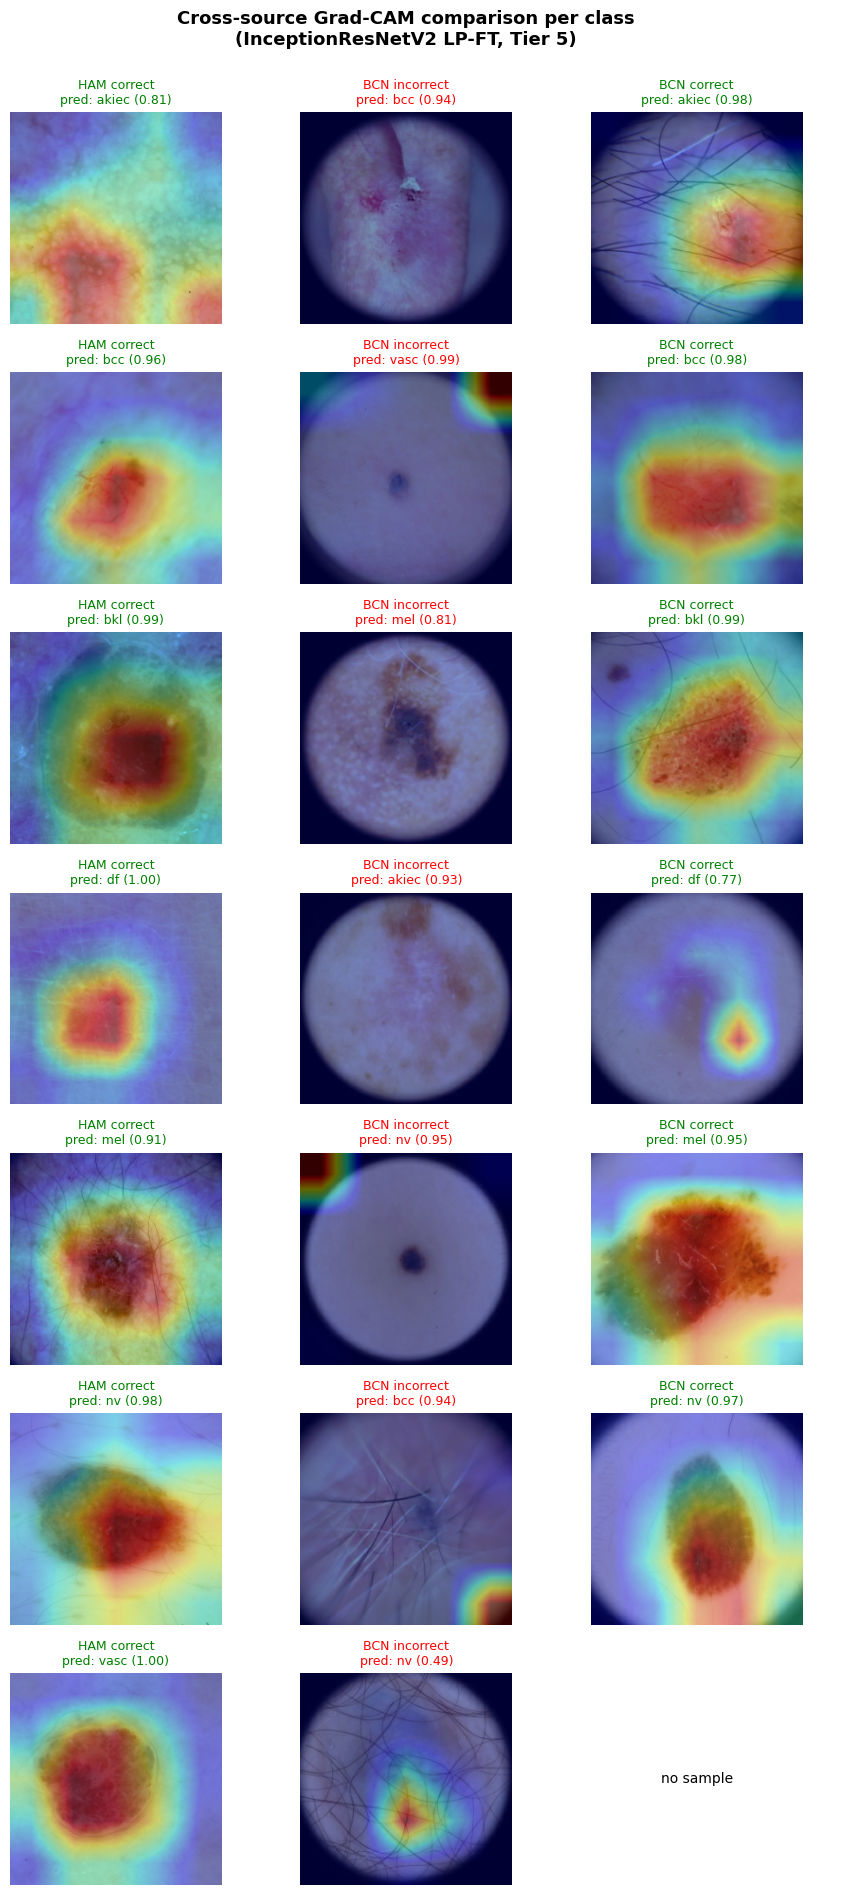

In [12]:
def first_for_class(set_df, cls):
    rows = set_df[set_df['true_class'] == cls]
    if len(rows) == 0:
        return None
    return rows.iloc[0]


fig, axes = plt.subplots(N_CLASSES, 3, figsize=(9, 2.7 * N_CLASSES))

for row_idx, cls in enumerate(CLASS_NAMES):
    for col_idx, (set_df, set_label) in enumerate([
        (set_A, 'HAM correct'),
        (set_B, 'BCN incorrect'),
        (set_C, 'BCN correct'),
    ]):
        ax = axes[row_idx, col_idx]
        r = first_for_class(set_df, cls)
        if r is None or r['image_id'] not in lookup:
            ax.text(0.5, 0.5, 'no sample', ha='center', va='center', transform=ax.transAxes)
            ax.axis('off')
            continue
        entry = lookup[r['image_id']]
        img = entry['image']
        true_label = entry['label']
        hm = compute_gradcam(img, true_label)
        _, ovl = overlay_heatmap(img, hm)
        ax.imshow(ovl)
        title = f"{set_label}\npred: {r['pred_class']} ({r['confidence']:.2f})"
        color = 'green' if r['correct'] else 'red'
        ax.set_title(title, fontsize=9, color=color)
        ax.axis('off')

    axes[row_idx, 0].set_ylabel(cls, fontsize=11, fontweight='bold', rotation=0,
                                  labelpad=25, va='center')

plt.suptitle('Cross-source Grad-CAM comparison per class\n(InceptionResNetV2 LP-FT, Tier 5)',
             fontsize=13, fontweight='bold', y=1.0)
plt.tight_layout()
out_path = OUTPUT_DIR / 'cross_source_comparison.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved: {out_path}')
plt.show()

## 13. Summary metadata

Salvăm un JSON cu config + accuracy per source pentru capitolul de teză.

In [13]:
summary = {
    'model': 'InceptionResNetV2',
    'protocol': 'LP-FT',
    'tier': 5,
    'checkpoint': str(MODEL_PATH),
    'target_conv_layer': TARGET_CONV_LAYER,
    'img_size': IMG_SIZE,
    'n_test_samples': int(len(df_pred)),
    'overall_accuracy': float(df_pred['correct'].mean()),
    'accuracy_per_source': {
        src: {
            'accuracy': float(g['correct'].mean()),
            'n': int(len(g)),
        }
        for src, g in df_pred.groupby('source')
    },
    'n_per_class_per_set': N_PER_CLASS_PER_SET,
    'sets': {
        'A_HAM_correct':   int(len(set_A)),
        'B_BCN_incorrect': int(len(set_B)),
        'C_BCN_correct':   int(len(set_C)),
    },
}

with open(OUTPUT_DIR / 'gradcam_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "model": "InceptionResNetV2",
  "protocol": "LP-FT",
  "tier": 5,
  "checkpoint": "/content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/B_lpft/final.keras",
  "target_conv_layer": "conv_7b_ac",
  "img_size": 224,
  "n_test_samples": 2513,
  "overall_accuracy": 0.703541583764425,
  "accuracy_per_source": {
    "BCN_20000": {
      "accuracy": 0.627831715210356,
      "n": 1236
    },
    "HAM10000": {
      "accuracy": 0.7939330543933054,
      "n": 956
    },
    "MSK": {
      "accuracy": 0.7258566978193146,
      "n": 321
    }
  },
  "n_per_class_per_set": 3,
  "sets": {
    "A_HAM_correct": 21,
    "B_BCN_incorrect": 21,
    "C_BCN_correct": 18
  }
}


## 14. Save Individual Grad-CAM Images

Save the individual original and overlay images for each candidate in the sets.

In [15]:
INDIVIDUAL_IMG_DIR = OUTPUT_DIR / 'individual_images'
ORIG_IMG_DIR = INDIVIDUAL_IMG_DIR / 'original'
GRADCAM_IMG_DIR = INDIVIDUAL_IMG_DIR / 'gradcam'

ORIG_IMG_DIR.mkdir(parents=True, exist_ok=True)
GRADCAM_IMG_DIR.mkdir(parents=True, exist_ok=True)

def save_individual_images(set_df, set_prefix):
    for _, row in set_df.iterrows():
        img_id = row['image_id']
        if img_id not in lookup:
            continue

        true_class = row['true_class']
        pred_class = row['pred_class']
        entry = lookup[img_id]
        img = entry['image']
        true_label = entry['label']

        # Compute Grad-CAM
        hm = compute_gradcam(img, true_label)
        orig, ovl = overlay_heatmap(img, hm)

        # Save original
        orig_path = ORIG_IMG_DIR / f"{set_prefix}_{true_class}_pred_{pred_class}_{img_id}_orig.jpg"
        plt.imsave(orig_path, orig)

        # Save overlay
        ovl_path = GRADCAM_IMG_DIR / f"{set_prefix}_{true_class}_pred_{pred_class}_{img_id}_gradcam.jpg"
        plt.imsave(ovl_path, ovl)

print(f'Saving individual images to:\n- {ORIG_IMG_DIR}\n- {GRADCAM_IMG_DIR}...')
save_individual_images(set_A, 'SetA')
save_individual_images(set_B, 'SetB')
save_individual_images(set_C, 'SetC')
print('Done saving individual images in separate directories.')

Saving individual images to:
- /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/B_lpft/gradcam_lpft/individual_images/original
- /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/B_lpft/gradcam_lpft/individual_images/gradcam...


/tmp/ipykernel_4084/3653350699.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl_cm.get_cmap('jet')


Done saving individual images in separate directories.


## Observații pentru teză

Pe măsură ce te uiți la grids:

- **Set A (HAM correct, high conf)**: model atent pe leziune? sau pe artefacte (păr, vignetă, marker dermatoscop)?
- **Set B (BCN incorrect, high conf)**: pe ce se uită modelul când e *încrezător dar greșit*? Indică shortcuts învățate pe HAM care nu generalizează (de ex., dark corners, magnification artifacts, vignetă).
- **Set C (BCN correct, high conf)**: control — când *funcționează* pe BCN, atenția arată similar cu Set A?

Compară cu rezultatele Grad-CAM EfficientNet — InceptionResNetV2 are arhitectură foarte
diferită (multi-scale inception modules), deci e plauzibil să vezi heatmap-uri mai
spread-out vs. EfficientNet care tinde să fie mai focused.